In [87]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy.signal import welch
from scipy.stats import kurtosis, skew
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score, roc_auc_score
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from tqdm import tqdm
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
import holidays
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import grangercausalitytests
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer

## Downloading the Dataset

In [88]:
df = pd.read_csv('train.csv')
df

,id,keyword,location,text,target
0,1,NaN,NaN,Our Deeds are the Reason of this #earthquake M...,1
1,4,NaN,NaN,Forest fire near La Ronge Sask. Canada,1
2,5,NaN,NaN,All residents asked to 'shelter in place' are ...,1
3,6,NaN,NaN,"13,000 people receive #wildfires evacuation or...",1
4,7,NaN,NaN,Just got sent this photo from Ruby #Alaska as ...,1
...,...,...,...,...,...
7608,10869,NaN,NaN,Two giant cranes holding a bridge collapse int...,1
7609,10870,NaN,NaN,@aria_ahrary @TheTawniest The out of control w...,1
7610,10871,NaN,NaN,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1
7611,10872,NaN,NaN,Police investigating after an e-bike collided ...,1


## Dataset Inspection

In [89]:
df = df.drop(columns=['id','location']) 
df.isna().sum()

keyword    61
text        0
target      0
dtype: int64

## Processing the Dataset

In [90]:
df = df.fillna('null')                              
df['inputs'] = df['keyword'] + ' ' + df['text'] 
df

,keyword,text,target,inputs
0,null,Our Deeds are the Reason of this #earthquake M...,1,null Our Deeds are the Reason of this #earthqu...
1,null,Forest fire near La Ronge Sask. Canada,1,null Forest fire near La Ronge Sask. Canada
2,null,All residents asked to 'shelter in place' are ...,1,null All residents asked to 'shelter in place'...
3,null,"13,000 people receive #wildfires evacuation or...",1,"null 13,000 people receive #wildfires evacuati..."
4,null,Just got sent this photo from Ruby #Alaska as ...,1,null Just got sent this photo from Ruby #Alask...
...,...,...,...,...
7608,null,Two giant cranes holding a bridge collapse int...,1,null Two giant cranes holding a bridge collaps...
7609,null,@aria_ahrary @TheTawniest The out of control w...,1,null @aria_ahrary @TheTawniest The out of cont...
7610,null,M1.94 [01:04 UTC]?5km S of Volcano Hawaii. htt...,1,null M1.94 [01:04 UTC]?5km S of Volcano Hawaii...
7611,null,Police investigating after an e-bike collided ...,1,null Police investigating after an e-bike coll...


## Splitting the Dataset into Train-Set (90-10%)

In [91]:
X = df['inputs'].to_numpy()
y = df['target'].to_numpy()

x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.1, stratify=y, random_state=0)
print(x_train.shape, x_test.shape, y_train.shape, y_test.shape)

(6851,) (762,) (6851,) (762,)


## Class Inspection

In [92]:
class_balance = pd.DataFrame({'Count': df['target'].value_counts(),'Percentage (%)': (df['target'].value_counts(normalize=True) * 100).round(2)})
class_balance

,Count,Percentage (%)
target,,
0,4342,57.03
1,3271,42.97


Classes are almost balanced, but stratified sampling has been used anyway for train-test split.

Size of each class of tweets (disaster or not) in the train set and the test set:

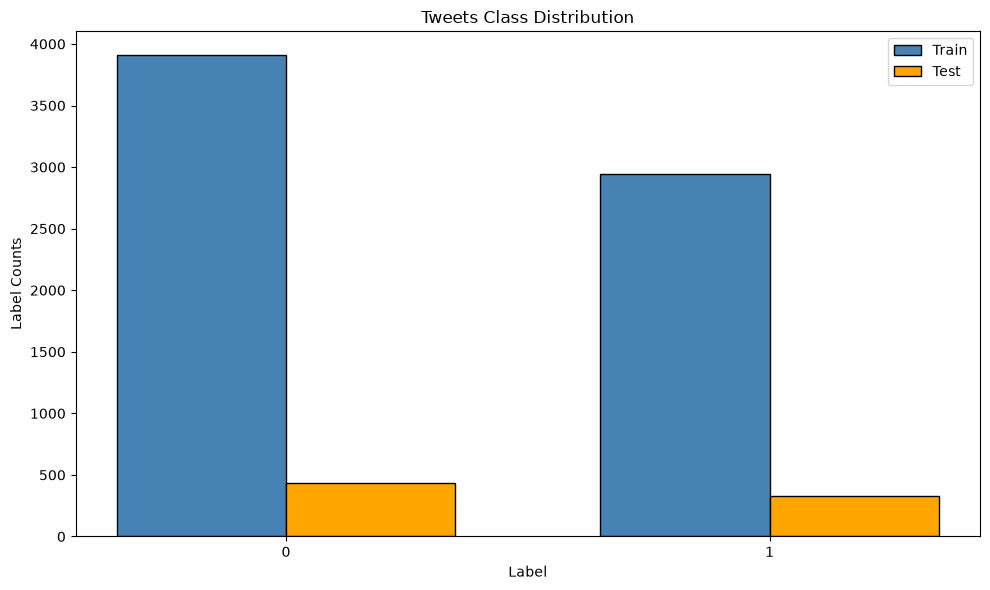

In [93]:
y_train_counts = pd.Series(y_train).value_counts().sort_index()
y_test_counts = pd.Series(y_test).value_counts().sort_index()

x = np.arange(y_train_counts.shape[0])
width = 0.35
plt.figure(figsize=(10, 6))
plt.bar(x - width/2, y_train_counts, width, label='Train', color='steelblue', edgecolor='black')
plt.bar(x + width/2, y_test_counts, width, label='Test', color='orange', edgecolor='black')

plt.title('Tweets Class Distribution')
plt.xlabel('Label')
plt.ylabel('Label Counts')
plt.xticks(x, y_train_counts.index)
plt.legend()
plt.tight_layout()
plt.show()

Proportion of each class of tweets in the train set and the test set:

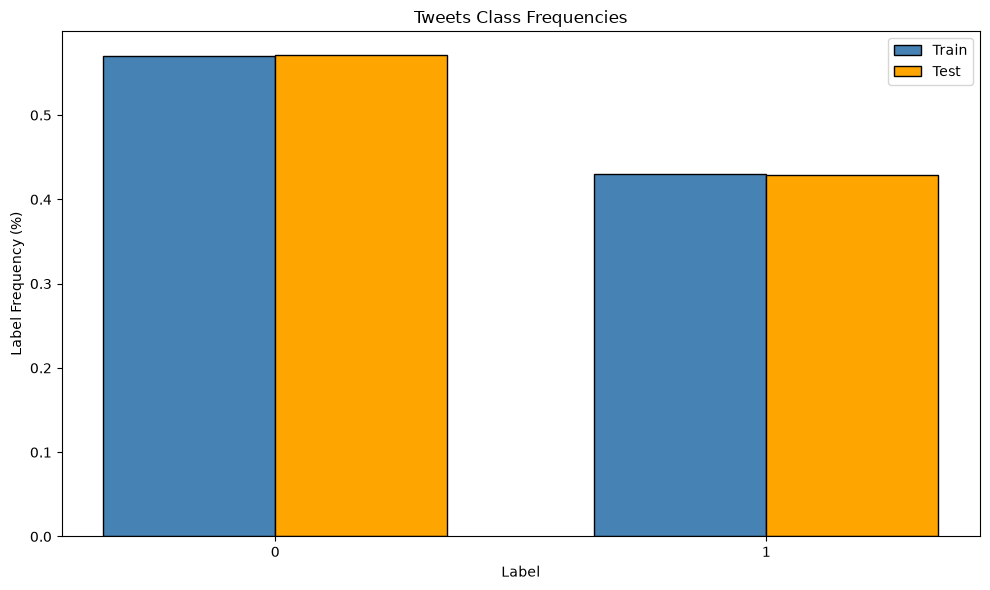

In [94]:
y_train_counts = pd.Series(y_train).value_counts(normalize=True).sort_index()
y_test_counts = pd.Series(y_test).value_counts(normalize=True).sort_index()

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, y_train_counts, width, label='Train', color='steelblue', edgecolor='black')
plt.bar(x + width/2, y_test_counts, width, label='Test', color='orange', edgecolor='black')

plt.title('Tweets Class Frequencies')
plt.xlabel('Label')
plt.ylabel('Label Frequency (%)')
plt.xticks(x, y_train_counts.index)
plt.legend()
plt.tight_layout()
plt.show()

The proportions of each class of tweets are almost equal in the train set and the test set. This shows the stratify has correctly worked

## Cleaning the text of the tweets

I start by importing all of the techniques from the Github

In [95]:
import html, string, warnings
import nltk
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

warnings.filterwarnings('ignore', category=SyntaxWarning)  # warnings sans gravité du vieux code du repo
from techniques import (removeUnicode, replaceURL, replaceAtUser, removeHashtagInFrontOfWord,
                        removeEmoticons, replaceSlang, replaceContraction, removeNumbers)

Here is a quick explanation of what each technique does:

- removeUnicode: Removes emojis and wrongly encoded text
- replaceURL: Replaces every link with the token `url`. The links are meaningless but their presence is not, that is why they are replaced with a token.
- replaceAtUser: Replaces every `@user` with `atuser` Same, the user name is meaningless but the present of @user is not.
- removeHashtagInFrontOfWord: Removes the `#` in front of a word.
- removeEmoticons: Removes text emoticons, they are meaningless.
- lower: Converts all characters to lowercase.
- replaceSlang: Replaces slang words with the real word, because they have the same meaning, so the classifier knows they are the same thing.
- replaceContraction: Expands contractions, because they have the same meaning.
- removeNumbers: They are often meaningless and expand the vocabulary a lot.
- punctuation: Removes punctuation characters, meaningless
- stopwords: Removes very common words (`the`) because they are in almost every tweet and do not help the classification.
- WordNetLemmatizer: Reduces words to their base form (`swallows` → `swallow`). It reduces the vocabulary and keeps the meaning.

I can then apply all of these techniques to the tweets' text.

In [96]:
stoplist = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()
punct = str.maketrans('', '', string.punctuation)

def clean(text):                
    text = removeUnicode(text)                 
    text = replaceURL(text)                    
    text = replaceAtUser(text)                 
    text = removeHashtagInFrontOfWord(text)    
    text = removeEmoticons(text)
    text = text.lower()                        
    text = replaceSlang(text)                  
    text = replaceContraction(text)            
    text = removeNumbers(text)                 
    text = text.translate(punct)               
    tokens = [lemmatizer.lemmatize(w) for w in text.split() if w not in stoplist]  
    return ' '.join(tokens)

x_train = np.array([clean(t) for t in x_train])
x_test = np.array([clean(t) for t in x_test])


## Checking if the text was properly cleaned

In [97]:
x_train
x_test

array(['bioterror fedex longer transport bioterror germ wake anthrax lab mishap url',
       'panic panic patient alabama test negative ebola url',
       'duststorm new mad max screenshots show lovely dust storm combat magnum opus url',
       'evacuated rocky fire northern california swell acre evacuated url portland phoenix miami atlanta casper',
       'lava atuser lava blast andamp power red atuser atuser pantherattack',
       'ambulance ambulance sprinter automatic frontline vehicle choice lez compliant ebay url',
       'massacre uk police link tunisian beach massacre bardo museum attack url',
       'demolish srsly demolish partner face andampstart dribbling nostril stop andampask urself whether really worth embarrassment',
       'crush woman crush wedneday go beautiful atuser loveyouuuu aintsheperty url',
       'army build kingdom lead army victory url start grin friend code lzktjnox url',
       'blight new post prysmian secures contract blight bank wind farm url',
       

The cleaning has worked: There are no emojis, URL, Usernames, #, capital letters, slang, contractions, numbers, punctuation or stopwords, and the words are all reduced to their base form.

## Vectorization using TF-IDF of the Data.


I will be fitting the vectorizer only on the training data and transforming both training and test data.

In [98]:
vectorizer = TfidfVectorizer(max_features=2000)
x_train_tfidf = vectorizer.fit_transform(x_train)   
x_test_tfidf  = vectorizer.transform(x_test) 

x_train_tfidf.shape, x_test_tfidf.shape

((6851, 2000), (762, 2000))

I have to make the data into dense arrays in order to use GaussianNB

In [99]:
x_train_dense = x_train_tfidf.toarray()
x_test_dense = x_test_tfidf.toarray()

## Training the Gaussian Naive Bayes classifier

I create the model, train it on the dataset, and check its accuracy on the test set.

In [100]:
model = GaussianNB()
model.fit(x_train_dense, y_train)

y_pred = model.predict(x_test_dense)
y_proba = model.predict_proba(x_test_dense)[:, 1]

print(f"Accuracy          : {accuracy_score(y_test, y_pred):.4f}")
print(f"Balanced accuracy : {balanced_accuracy_score(y_test, y_pred):.4f}")
print(f"Precision         : {precision_score(y_test, y_pred):.4f}")
print(f"Recall            : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score          : {f1_score(y_test, y_pred):.4f}")
print(f"ROC AUC           : {roc_auc_score(y_test, y_proba):.4f}")



Accuracy          : 0.7861
Balanced accuracy : 0.7671
Precision         : 0.8280
Recall            : 0.6330
F1-score          : 0.7175
ROC AUC           : 0.8287


The scores are correct, the model works.